<div style="background:#080c10;border:1px solid #00d4ff;border-radius:10px;padding:26px 30px;">
<div style="color:#00d4ff;font-size:12px;letter-spacing:2px;font-weight:600;">OLIVIER SPORTS DATA · FROM CHICKEN AREA 🐔</div>
<div style="color:#ffffff;font-size:30px;font-weight:700;margin:10px 0 6px 0;">NCAAB V2 — Verify Before You Buy</div>
<div style="color:#9fb3bf;font-size:15px;">79,780 games · 2008/09 → 2 November 2026 · NCAA Tournament · closing odds</div>
</div>

This notebook runs on the **full file**, the same `NCAAB_Closing_Odds.csv` that is delivered on Gumroad, not on the public sample.
Every table and chart below is computed live from that file. Its SHA-256 fingerprint is printed first, so you can check that it is the file of the product.
The same file is also the NCAAB file of the US Sports Master V2.

**Contents:** 1. Coverage by season · 2. Integrity checks · 3. The figures of the product page · 4. Are the closing odds calibrated? · 5. Bookmaker margin over time · 6. Favourites, home court and March Madness upsets · 7. What you get

**Source:** OddsPortal. The odds are the average closing prices shown by the source, not attributable to any single bookmaker.


In [1]:
import glob, hashlib, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter, MaxNLocator
from IPython.display import display
warnings.filterwarnings("ignore")

# Signature colours: dark surface, one cyan accent, cool grey ink
BG, CYAN = "#080c10", "#00d4ff"
INK, INK2, MUTED = "#e8f1f5", "#9fb3bf", "#6b7d88"
GRID, AXIS, REF = "#16212b", "#2a3a46", "#56646e"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "text.color": INK, "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})
THOUSANDS = FuncFormatter(lambda v, _: f"{v:,.0f}")


def show(df, caption=None):
    """Dark table in the notebook signature."""
    sty = df.style.set_table_styles([
        {"selector": "th", "props": [("background-color", "#0f1820"), ("color", CYAN), ("font-weight", "600"),
                                     ("border", "1px solid #1c2a35"), ("padding", "6px 10px"), ("text-align", "left")]},
        {"selector": "td", "props": [("background-color", BG), ("color", INK), ("border", "1px solid #1c2a35"),
                                     ("padding", "5px 10px"), ("text-align", "left")]},
        {"selector": "caption", "props": [("color", INK2), ("caption-side", "top"), ("text-align", "left"),
                                          ("padding", "4px 0 8px 0"), ("font-size", "13px")]},
    ]).hide(axis="index")
    if caption:
        sty = sty.set_caption(caption)
    display(sty)

In [2]:
INPUT = "/kaggle/input"
EXPECTED_SHA256 = "7748ca06aef0d849f4cfcaf4a516a7b43b23ccf498344fb5622c979007ce5e2c"   # NCAAB_Closing_Odds.csv in NCAAB_Closing_Odds_V2.zip


def find_file():
    found = [f for f in sorted(glob.glob(os.path.join(INPUT, "**", "NCAAB_Closing_Odds.csv"), recursive=True))
             if "SAMPLE" not in f.upper()]
    if not found:
        raise FileNotFoundError(f"NCAAB_Closing_Odds.csv was not found under {INPUT}")
    return found[0]


def num(s):
    return pd.to_numeric(s.replace("", np.nan), errors="coerce")


def implied(american):
    """American odds -> implied probability (with the bookmaker margin still inside)."""
    a = np.asarray(american, dtype=float)
    dec = np.where(a > 0, 1 + a / 100, 1 + 100 / np.abs(a))
    return 1 / dec


FILE = find_file()
sha = hashlib.sha256(open(FILE, "rb").read()).hexdigest()
RAW = pd.read_csv(FILE, encoding="utf-8-sig", dtype=str, keep_default_na=False)

D = RAW.copy()                       # typed copy
for c in ["Home_Score", "Away_Score", "Total_Score", "Margin", "Home_Odds", "Draw_Odds", "Away_Odds", "Bookmakers"]:
    D[c] = num(D[c])
D["Season_Start"] = D["Season"].str[:4].astype(int)
D["ih"], D["ia"] = implied(D["Home_Odds"]), implied(D["Away_Odds"])
PLAYED = D["Home_Score"].notna()
TOURNEY = D["Stage"] == "Play Offs"

print(f"File: {os.path.basename(FILE)}  ·  {len(RAW):,} rows  ·  {RAW.shape[1]} columns")
print(f"SHA-256: {sha}")
print("✔ Same file as the one delivered on Gumroad" if sha == EXPECTED_SHA256 else "✘ This is not the file delivered on Gumroad")

File: NCAAB_Closing_Odds.csv  ·  79,780 rows  ·  18 columns
SHA-256: 7748ca06aef0d849f4cfcaf4a516a7b43b23ccf498344fb5622c979007ce5e2c
✔ Same file as the one delivered on Gumroad


## 1. Coverage by season

One row per season. `Played` counts the games with a final score; cancelled, postponed and awarded games are kept, with no score.
`NCAA Tournament` counts the games of Stage `Play Offs`. Conference tournaments are part of `Regular Season`, as the source lists them.
The first season starts on 20 November 2008 and stops on 7 March 2009; the last one has just started (games up to 2 November 2026, North American time).

Season,Rows,Played,No score,NCAA Tournament,Overtime,Both prices,First game,Last game
2008/2009,774,774,0,0,50,660,2008-11-20,2009-03-07
2009/2010,"3,318","3,315",3,63,192,"3,070",2009-11-20,2010-04-06
2010/2011,"3,579","3,578",1,67,225,"3,330",2010-11-09,2011-04-05
2011/2012,"3,667","3,667",0,67,224,"3,480",2011-11-08,2012-04-03
2012/2013,"3,821","3,818",3,67,229,"3,561",2012-11-09,2013-04-09
2013/2014,"4,080","4,071",9,67,275,"3,708",2013-11-08,2014-04-08
2014/2015,"4,135","4,130",5,67,290,"3,989",2014-11-14,2015-04-07
2015/2016,"4,107","4,097",10,67,247,"3,908",2015-11-13,2016-04-05
2016/2017,"4,098","4,095",3,67,250,"3,981",2016-11-12,2017-04-04
2017/2018,"4,431","4,429",2,67,301,"4,296",2017-11-10,2018-04-03


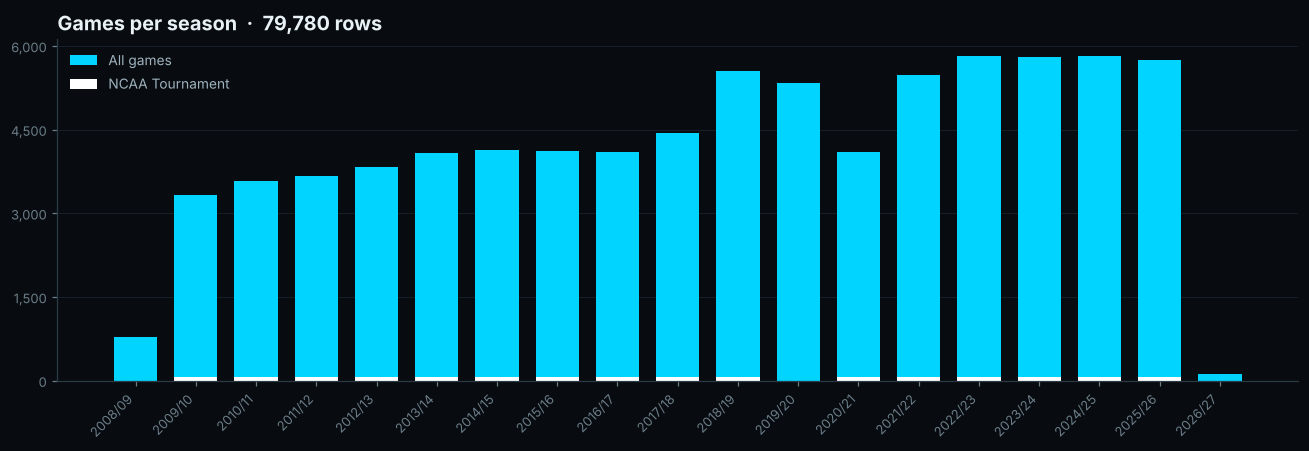

In [3]:
by = D.groupby("Season")
cov = pd.DataFrame({
    "Rows": by.size(),
    "Played": by.apply(lambda d: int(d["Home_Score"].notna().sum())),
    "No score": by.apply(lambda d: int(d["Home_Score"].isna().sum())),
    "NCAA Tournament": by.apply(lambda d: int((d["Stage"] == "Play Offs").sum())),
    "Overtime": by.apply(lambda d: int((d["Match_Ending"] == "Overtime").sum())),
    "Both prices": by.apply(lambda d: int((d["Home_Score"].notna() & d["Home_Odds"].notna() & d["Away_Odds"].notna()).sum())),
    "First game": by["Date"].min(), "Last game": by["Date"].max(),
}).reset_index()
tot = {"Season": "Total", "First game": D["Date"].min(), "Last game": D["Date"].max()}
for c in ["Rows", "Played", "No score", "NCAA Tournament", "Overtime", "Both prices"]:
    tot[c] = int(cov[c].sum())
cov = pd.concat([cov, pd.DataFrame([tot])], ignore_index=True)
out = cov.copy()
for c in ["Rows", "Played", "No score", "NCAA Tournament", "Overtime", "Both prices"]:
    out[c] = out[c].map("{:,}".format)
show(out, "Games per season")

c = D.groupby("Season_Start").size()
t = D[TOURNEY].groupby("Season_Start").size().reindex(c.index, fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(c.index, c.values, width=0.72, color=CYAN, linewidth=0, label="All games")
ax.bar(t.index, t.values, width=0.72, color="#ffffff", linewidth=0, label="NCAA Tournament")
ax.yaxis.set_major_formatter(THOUSANDS); ax.yaxis.set_major_locator(MaxNLocator(5))
ax.set_xticks(c.index, [f"{y}/{str(y + 1)[2:]}" for y in c.index], rotation=45, ha="right")
ax.grid(axis="x", visible=False)
ax.set_title(f"Games per season  ·  {len(D):,} rows", fontsize=13)
ax.legend(loc="upper left", fontsize=9, labelcolor=INK2)
fig.tight_layout()
plt.show()

## 2. Integrity checks

Each check runs on **every row it applies to** (see *Values checked*). ✔ means no row fails it.

In [4]:
checks = []
def add(check, n_checked, issues):
    checks.append({"Check": check, "Values checked": f"{n_checked:,}", "Issues": f"{issues:,}",
                   "Result": "✔" if issues == 0 else "✘"})

N = len(RAW)
COLS = ["League", "Season", "Stage", "Date", "Time", "Home_Team", "Away_Team", "Home_Score", "Away_Score", "Winner",
        "Total_Score", "Margin", "Match_Ending", "Final_Result_Only", "Home_Odds", "Draw_Odds", "Away_Odds", "Bookmakers"]
add("The 18 columns of the US Sports Master team files, same order", 18, int(list(RAW.columns) != COLS))
add("League is NCAAB on every row", N, int((RAW["League"] != "NCAAB").sum()))
add("Season is written YYYY/YYYY", N, int((~RAW["Season"].str.fullmatch(r"\d{4}/\d{4}")).sum()))
bad = (~RAW["Date"].str.fullmatch(r"\d{4}-\d{2}-\d{2}")) | pd.to_datetime(RAW["Date"], errors="coerce").isna()
add("Date is a valid ISO 8601 date (YYYY-MM-DD)", N, int(bad.sum()))
y = D["Date"].str[:4].astype(int)
add("Date falls inside its season", N, int(((y != D["Season_Start"]) & (y != D["Season_Start"] + 1)).sum()))
add("Time is HH:MM when present", N, int((~RAW["Time"].str.fullmatch(r"(?:[01]\d|2[0-3]):[0-5]\d") & (RAW["Time"] != "")).sum()))
add("Stage is Regular Season or Play Offs", N, int((~RAW["Stage"].isin(["Regular Season", "Play Offs"])).sum()))
ENDINGS = {"Regular Time", "Overtime", "Cancelled", "Postponed", "Awarded"}
add("Match_Ending is Regular Time, Overtime, Cancelled, Postponed or Awarded", N, int((~RAW["Match_Ending"].isin(ENDINGS)).sum()))
played_end = RAW["Match_Ending"].isin(["Regular Time", "Overtime"])
add("A score exactly on the games played (regular time or overtime)", N, int((played_end != PLAYED).sum()))
w = np.select([D["Home_Score"] > D["Away_Score"], D["Home_Score"] < D["Away_Score"]], ["Home", "Away"], default="")
add("Winner matches the final score (Home or Away, no draw)", N, int((w != D["Winner"]).sum()))
p = D[PLAYED]
add("Total_Score and Margin match the scores", len(p),
    int(((p["Home_Score"] + p["Away_Score"] != p["Total_Score"]) | ((p["Home_Score"] - p["Away_Score"]).abs() != p["Margin"])).sum()))
vals = pd.concat([D["Home_Odds"], D["Away_Odds"]]).dropna()
add("Odds are valid American prices (≤ −100 or ≥ +100)", len(vals), int((vals.abs() < 100).sum()))
pr = D.dropna(subset=["ih", "ia"])
add("Closing prices are consistent (implied probabilities sum to 100 % or more)", len(pr), int((pr["ih"] + pr["ia"] < 1).sum()))
add("Draw_Odds is empty (two-way market)", N, int(D["Draw_Odds"].notna().sum()))
add("No exact duplicate row", N, int(RAW.duplicated().sum()))
add("No game listed twice (same date, time and teams)", N, int(RAW.duplicated(["Date", "Time", "Home_Team", "Away_Team"]).sum()))
add("A team never plays itself", N, int((RAW["Home_Team"] == RAW["Away_Team"]).sum()))
per = D[TOURNEY].groupby("Season").size()
exp = {s: (63 if s == "2009/2010" else 67) for s in per.index}
add("NCAA Tournament: 67 games a year from 2011, 63 in 2010", len(per), int(sum(per[s] != exp[s] for s in per.index)))
bk = D["Bookmakers"].dropna()
add("Bookmakers: 1 to 9, filled up to 2018/2019, empty from 2019/2020", N,
    int((~bk.between(1, 9)).sum() + (D["Bookmakers"].isna() & (D["Season_Start"] <= 2018)).sum()
        + (D["Bookmakers"].notna() & (D["Season_Start"] >= 2019)).sum()))
fro = RAW["Final_Result_Only"]
add("Final_Result_Only: Yes or No up to 23 March 2026, empty after", N,
    int((~fro.isin(["Yes", "No", ""])).sum() + ((fro == "") & (RAW["Date"] <= "2026-03-23")).sum()
        + ((fro != "") & (RAW["Date"] > "2026-03-23")).sum()))

show(pd.DataFrame(checks), "Integrity checks")
print(f"Note: Time is empty on {int((RAW['Time'] == '').sum())} row(s), all dated {', '.join(sorted(RAW.loc[RAW['Time'] == '', 'Date'].unique()))}.")
pairs = RAW[RAW.duplicated(["Date", "Home_Team", "Away_Team"], keep=False)]
by_season = pairs.groupby("Season").size() // 2
print(f"Note: {len(pairs) // 2} pairs of games share the same date and the same two teams, at different times "
      f"({', '.join(f'{s}: {n}' for s, n in by_season.items())}). In 2020/2021, conferences played back-to-back series: "
      "the first game, in the US evening, falls after midnight in Paris. Use Date, Time and both teams to identify a game.")

Check,Values checked,Issues,Result
"The 18 columns of the US Sports Master team files, same order",18,0,✔
League is NCAAB on every row,"79,780",0,✔
Season is written YYYY/YYYY,"79,780",0,✔
Date is a valid ISO 8601 date (YYYY-MM-DD),"79,780",0,✔
Date falls inside its season,"79,780",0,✔
Time is HH:MM when present,"79,780",0,✔
Stage is Regular Season or Play Offs,"79,780",0,✔
"Match_Ending is Regular Time, Overtime, Cancelled, Postponed or Awarded","79,780",0,✔
A score exactly on the games played (regular time or overtime),"79,780",0,✔
"Winner matches the final score (Home or Away, no draw)","79,780",0,✔


Note: Time is empty on 6 row(s), all dated 2026-11-03.
Note: 148 pairs of games share the same date and the same two teams, at different times (2017/2018: 1, 2020/2021: 147). In 2020/2021, conferences played back-to-back series: the first game, in the US evening, falls after midnight in Paris. Use Date, Time and both teams to identify a game.


## 3. The figures of the product page

The figures of the product page, recomputed from the file.

In [5]:
one_or_none = int((PLAYED & (D["Home_Odds"].isna() | D["Away_Odds"].isna())).sum())
claims = [
    ("Rows", "79,780", f"{len(D):,}"),
    ("Games played", "79,452", f"{int(PLAYED.sum()):,}"),
    ("Cancelled, postponed or awarded", "328", f"{int((~PLAYED).sum()):,}"),
    ("Seasons", "19 (2008/09 to 2026/27)", f"{D['Season'].nunique()} ({D['Season'].min()[:5]}{D['Season'].min()[7:]} to {D['Season'].max()[:5]}{D['Season'].max()[7:]})"),
    ("NCAA Tournaments", "16 (2010 to 2026)", f"{D.loc[TOURNEY, 'Season'].nunique()} ({D.loc[TOURNEY, 'Date'].min()[:4]} to {D.loc[TOURNEY, 'Date'].max()[:4]})"),
    ("NCAA Tournament games", "1,068", f"{int(TOURNEY.sum()):,}"),
    ("Games played with both closing prices", "76,320", f"{int((PLAYED & D['Home_Odds'].notna() & D['Away_Odds'].notna()).sum()):,}"),
    ("Games played without a price for one or both sides", "3,132", f"{one_or_none:,}"),
    ("Overtime games", "4,783", f"{int((D['Match_Ending'] == 'Overtime').sum()):,}"),
    ("Team names", "686", f"{pd.concat([D['Home_Team'], D['Away_Team']]).nunique():,}"),
    ("First game", "2008-11-20", D["Date"].min()),
    ("Last game", "2026-11-03", D["Date"].max()),
    ("Games of 2026/27 so far", "121", f"{int((D['Season'] == '2026/2027').sum()):,}"),
]
cl = pd.DataFrame(claims, columns=["Figure", "Product page", "Computed from the file"])
cl["Result"] = np.where(cl["Product page"] == cl["Computed from the file"], "✔", "✘")
show(cl, "Product page vs. file")
print(f"{int((cl['Result'] == '✔').sum())} of {len(cl)} figures match.")

Figure,Product page,Computed from the file,Result
Rows,"79,780","79,780",✔
Games played,"79,452","79,452",✔
"Cancelled, postponed or awarded",328,328,✔
Seasons,19 (2008/09 to 2026/27),19 (2008/09 to 2026/27),✔
NCAA Tournaments,16 (2010 to 2026),16 (2010 to 2026),✔
NCAA Tournament games,"1,068","1,068",✔
Games played with both closing prices,"76,320","76,320",✔
Games played without a price for one or both sides,"3,132","3,132",✔
Overtime games,"4,783","4,783",✔
Team names,686,686,✔


13 of 13 figures match.


## 4. Are the closing odds calibrated?

If the closing prices are genuine, a side priced at 70 % should win about 70 % of the time.
The odds are converted to probabilities with the bookmaker margin removed, grouped in 5-point bins,
and compared with how often the home side (the first team listed) actually won. Points on the grey diagonal mean well-calibrated prices.
`Error` is the gap between priced and observed frequency, averaged over all games, in percentage points.

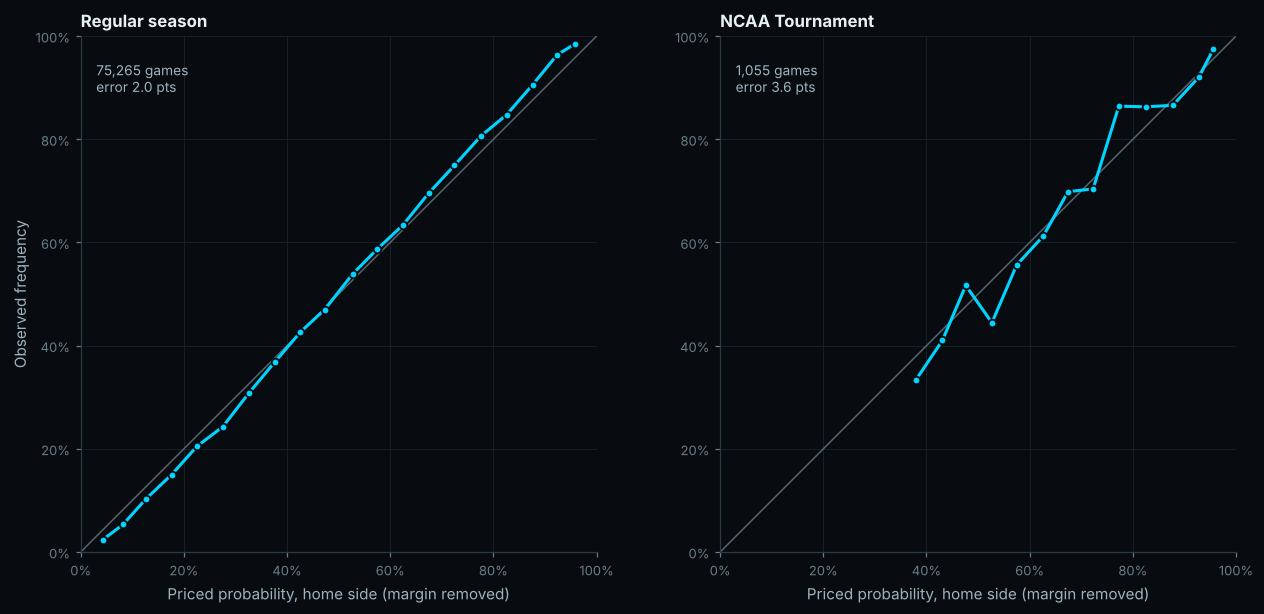

Games,Games used,Priced (mean),Observed,Error (pts),Brier score
Regular season,"75,265",61.9%,63.1%,2.0,0.178
NCAA Tournament,"1,055",68.1%,68.2%,3.6,0.188


In [6]:
def bins(p, y, width=0.05):
    b = np.clip((p / width).astype(int), 0, int(round(1 / width)) - 1)
    return pd.DataFrame({"b": b, "p": p, "y": y}).groupby("b").agg(n=("y", "size"), p=("p", "mean"), y=("y", "mean"))


d = D[PLAYED].dropna(subset=["ih", "ia"])
summary = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, (label, part) in zip(axes, [("Regular season", d[d["Stage"] == "Regular Season"]), ("NCAA Tournament", d[d["Stage"] == "Play Offs"])]):
    p = (part["ih"] / (part["ih"] + part["ia"])).values
    y = (part["Winner"] == "Home").astype(int).values
    t = bins(p, y)
    err = float((t["n"] * (t["p"] - t["y"]).abs()).sum() / t["n"].sum())
    shown = t[t["n"] >= 25]
    ax.plot([0, 1], [0, 1], color=REF, linewidth=1)
    ax.plot(shown["p"], shown["y"], color=CYAN, linewidth=2, marker="o", markersize=5, markeredgecolor=BG, markeredgewidth=1.2)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(label)
    ax.set_xlabel("Priced probability, home side (margin removed)")
    ax.text(0.03, 0.95, f"{len(p):,} games\nerror {100 * err:.1f} pts", transform=ax.transAxes, va="top", fontsize=9, color=INK2)
    summary.append({"Games": label, "Games used": f"{len(p):,}", "Priced (mean)": f"{p.mean():.1%}",
                    "Observed": f"{y.mean():.1%}", "Error (pts)": f"{100 * err:.1f}", "Brier score": f"{np.mean((p - y) ** 2):.3f}"})
axes[0].set_ylabel("Observed frequency")
fig.tight_layout()
plt.show()
show(pd.DataFrame(summary), "Calibration summary (bins with at least 25 games are drawn)")

## 5. Bookmaker margin over time

Margin (overround) = sum of the two implied probabilities − 1, on the closing odds; median per season.

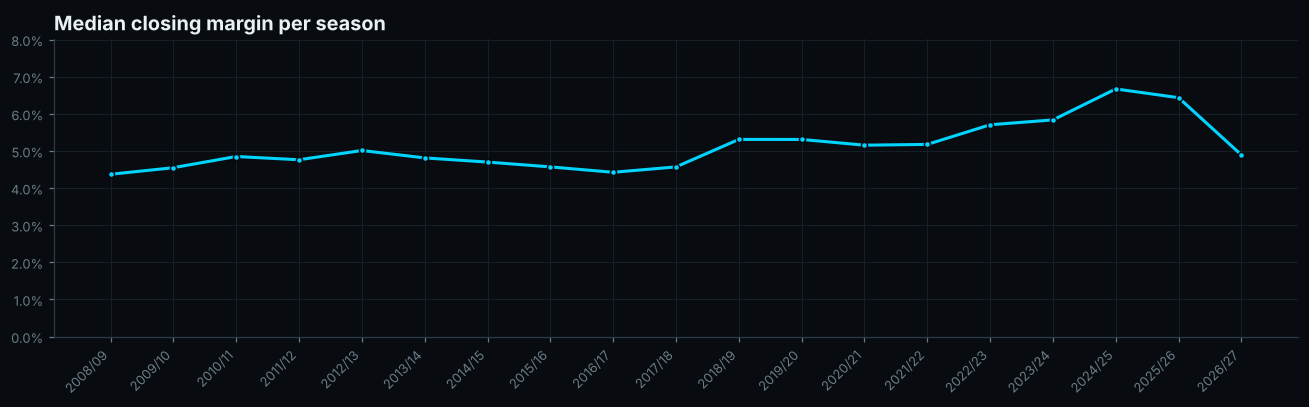

Season,Median margin,Rows with both prices
2008/2009,4.4%,660
2009/2010,4.5%,"3,073"
2010/2011,4.9%,"3,330"
2011/2012,4.8%,"3,480"
2012/2013,5.0%,"3,564"
2013/2014,4.8%,"3,710"
2014/2015,4.7%,"3,993"
2015/2016,4.6%,"3,915"
2016/2017,4.4%,"3,982"
2017/2018,4.6%,"4,298"


In [7]:
m = D.dropna(subset=["ih", "ia"])
med = (m["ih"] + m["ia"] - 1).groupby(m["Season_Start"]).median()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(med.index, med.values, color=CYAN, linewidth=2, marker="o", markersize=4, markeredgecolor=BG)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_xticks(med.index, [f"{y}/{str(y + 1)[2:]}" for y in med.index], rotation=45, ha="right")
ax.set_ylim(0, max(0.08, float(med.max()) * 1.2))
ax.set_title("Median closing margin per season", fontsize=13)
fig.tight_layout()
plt.show()
show(pd.DataFrame({"Season": [f"{y}/{y + 1}" for y in med.index], "Median margin": [f"{v:.1%}" for v in med.values],
                   "Rows with both prices": m.groupby("Season_Start").size().map("{:,}".format).values}), "Median margin per season")

## 6. Favourites, home court and March Madness upsets

The closing favourite is the side with the higher priced probability (margin removed).
The file has no neutral-site flag: in NCAA Tournament games, "home" is only the first team listed by the source, on a neutral court.

In [8]:
d = D[PLAYED].dropna(subset=["ih", "ia"]).copy()
d["ph"] = d["ih"] / (d["ih"] + d["ia"])
d = d[d["ph"] != 0.5]
d["fav_p"] = np.maximum(d["ph"], 1 - d["ph"])
d["fav_won"] = np.where(d["ph"] > 0.5, d["Winner"] == "Home", d["Winner"] == "Away")
rows = []
for label, part in [("All games", d), ("Regular season", d[d["Stage"] == "Regular Season"]), ("NCAA Tournament", d[d["Stage"] == "Play Offs"])]:
    rows.append({"Games": label, "Count": f"{len(part):,}", "Favourite won": f"{part['fav_won'].mean():.1%}",
                 "Priced": f"{part['fav_p'].mean():.1%}", "Home (first listed) won": f"{(part['Winner'] == 'Home').mean():.1%}"})
show(pd.DataFrame(rows), "Favourites and home court")

t = d[d["Stage"] == "Play Offs"].copy()
t["Underdog"] = np.where(t["ph"] > 0.5, t["Away_Team"], t["Home_Team"])
t["Favourite"] = np.where(t["ph"] > 0.5, t["Home_Team"], t["Away_Team"])
t["Underdog odds"] = np.where(t["ph"] > 0.5, t["Away_Odds"], t["Home_Odds"])
t["Favourite odds"] = np.where(t["ph"] > 0.5, t["Home_Odds"], t["Away_Odds"])
up = t[~t["fav_won"]].sort_values("Underdog odds", ascending=False).head(10)
up = up.assign(Score=up["Home_Team"] + " " + up["Home_Score"].astype(int).astype(str) + " – " + up["Away_Score"].astype(int).astype(str) + " " + up["Away_Team"])
show(pd.DataFrame({"Date": up["Date"], "Winner (underdog)": up["Underdog"], "Closing odds": up["Underdog odds"].map(lambda v: f"+{v:,.0f}"),
                   "Beat": up["Favourite"], "Favourite odds": up["Favourite odds"].map(lambda v: f"{v:,.0f}"), "Final score": up["Score"]}),
     "NCAA Tournament: the 10 biggest upsets by closing odds")

Games,Count,Favourite won,Priced,Home (first listed) won
All games,"76,183",73.0%,71.0%,63.2%
Regular season,"75,129",73.0%,71.0%,63.2%
NCAA Tournament,"1,054",70.1%,70.2%,68.1%


Date,Winner (underdog),Closing odds,Beat,Favourite odds,Final score
2018-03-17,UMBC Retrievers,"+2,032",Virginia,"-10,000",Virginia 54 – 74 UMBC Retrievers
2016-03-18,Middle Tenn. St.,"+1,782",Michigan State,"-5,000",Michigan State 81 – 90 Middle Tenn. St.
2012-03-16,Norfolk State,"+1,632",Missouri,"-10,000",Missouri 84 – 86 Norfolk State
2023-03-17,Fairleigh Dickinson,"+1,600",Purdue,"-10,000",Purdue 58 – 63 Fairleigh Dickinson
2022-03-18,St. Peters,"+1,220",Kentucky,"-3,333",Kentucky 79 – 85 St. Peters
2021-03-19,Oral Roberts,+896,Ohio State,"-2,000",Ohio State 72 – 75 Oral Roberts
2015-03-19,UAB,+871,Iowa State,"-1,667",Iowa State 59 – 60 UAB
2010-03-19,Ohio,+831,Georgetown,"-1,429",Georgetown 83 – 97 Ohio
2018-03-16,Marshall,+763,Wichita State,"-1,429",Wichita State 75 – 81 Marshall
2013-03-22,Florida Gulf Coast,+736,Georgetown,"-1,250",Georgetown 68 – 78 Florida Gulf Coast


## 7. What you get

* **1 CSV file in 1 ZIP** (`NCAAB_Closing_Odds.csv`) + `README.md` with the data dictionary
* **79,780 rows**: 79,452 games played and 328 cancelled, postponed or awarded, **20 November 2008 → 3 November 2026** (Paris dates)
* **NCAA Tournament**: 1,068 games, 16 tournaments (2010 to 2026; none in 2020), 67 games a year since 2011, First Four included; conference tournaments under `Regular Season`
* Closing moneyline odds (two-way, overtime included), American format: both prices for 76,320 games played
* Scores, winner, total, margin and how the game ended (regular time, overtime, cancelled, postponed, awarded)
* The same 18 columns as the other team sports of the US Sports Master: UTF-8 with BOM, comma-separated, ISO dates, Central European Time, home team first: `pd.read_csv()` ready
* Not inside: opening odds, line movement, spreads, totals, a neutral-site flag, NIT and CBI games (one CIT game of 2015 is in the file, listed in the README). 2008/2009 stops on 7 March 2009 (no NCAA Tournament that season). `Bookmakers` is filled up to 2018/2019 and `Final_Result_Only` up to 23 March 2026
* A few source errors are kept as the source shows them and listed in the README (for example, postponed games also shown as cancelled on their first date)

**Source:** OddsPortal. The odds are the average closing prices shown by the source, not attributable to any single bookmaker.

👉 [Get the full file on Gumroad](https://sportsdataolivier.gumroad.com/l/chbrtv?utm_source=github&utm_medium=notebook&utm_campaign=ncaab)

New games every month: the 2026/27 season goes on in the [US Sports Master monthly updates](https://sportsdataolivier.gumroad.com/l/mudppx?utm_source=github&utm_medium=notebook&utm_campaign=ncaab).

All 9 US leagues in one ZIP, NCAAB included: [US Sports Master](https://sportsdataolivier.gumroad.com/l/ahlplc?utm_source=github&utm_medium=notebook&utm_campaign=ncaab)

*Olivier Sports Data — From Chicken Area 🐔*
